In [9]:
import numpy as np
import matplotlib.pyplot as plt

from semester_project.gradient_descent import newton_descent
from semester_project.utils import FloatArray, OptimizationResult

In [10]:
rng = np.random.default_rng(42)

## Task 1

In [57]:
def function_newton(
    f_der,
    f_der2,
    x_0,
    epsi=1.e-6,
    max_steps=5):
    def pseudo_objective(beta: FloatArray) -> OptimizationResult: 
        beta = np.atleast_1d(beta)
        if beta.ndim > 1:
            raise ValueError(f"objective shape: we use functions R -> R here, got {beta} of dims: {beta.ndim}")
        if len(beta) != 1:
            raise ValueError(f"objective shape: we use functions R -> R here, got {beta}")
        return float(beta[0])

    def gradient(beta: FloatArray) -> FloatArray:
        beta = np.atleast_1d(beta)
        if beta.ndim > 1:
            raise ValueError(f"gradient shape: we use functions R -> R here, got {beta} of dims: {beta.ndim}")
        return np.array(f_der(beta))

    def hessian(beta: FloatArray) -> FloatArray:
        beta = np.atleast_1d(beta)
        if beta.ndim > 1:
            raise ValueError(f"hessian shape: we use functions R -> R here, got {beta} of dims: {beta.ndims}")
        return np.array([f_der2(beta)])
    
    opti_result = newton_descent(pseudo_objective, gradient=gradient, hessian=hessian, beta_0=x_0, epsi=epsi, max_steps=max_steps )
        
    converged = opti_result.converged    
    # if not converged:
    #     raise Exception("Newton’s method does not converge")
    # else:
    return opti_result

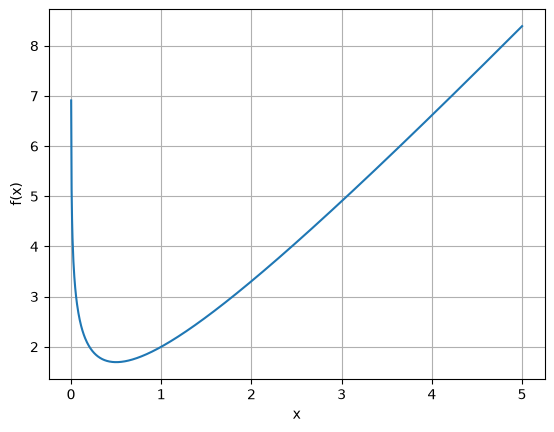

In [58]:
def experiment_fun_1(x: float) -> float:
    return 2 * x - np.log(x)

def experiment_fun_1_der(x: float) -> float:
    return 2 - 1 / x

def experiment_fun_1_der2(x: float) -> float:
    return 1 / x ** 2


x = np.linspace(0.001, 5, 1000)
y = experiment_fun_1(x)

plt.plot(x, y)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.show()

Compute derivative: $f' = 2 - \frac{1}{x}$;
Compute second derivative: $f'' = \frac{1}{x^2}$;
stationary points: $x = 1/2$, it is a minimum

[4.51804519 0.48698802 2.72111855 3.98818318 3.47021688 2.10390216]


/var/folders/vg/3f8hkwp17zn2s7j58fgv92gh0000gn/T/ipykernel_36519/366915281.py:2: RuntimeWarning: invalid value encountered in log
  return 2 * x - np.log(x)


ValueError: operands could not be broadcast together with shapes (12,) (6,) 

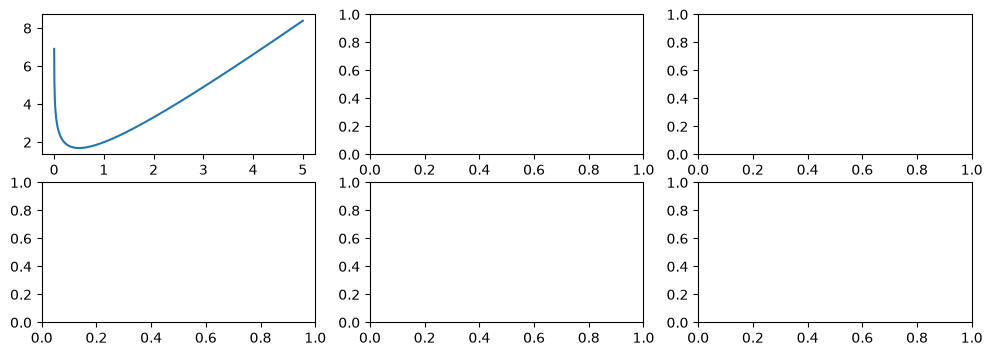

In [60]:
# Newton's method for this funciton: 
x = np.linspace(0.001, 5, 1000)
y = experiment_fun_1(x)
betas_start = 5 * (1 - rng.random((6, ))) # uniform on (0, 5]
print(betas_start)

fig, ax = plt.subplots(2, 3, figsize=(12, 4))
for i in range(6): 
    this_optimization = function_newton(experiment_fun_1_der, experiment_fun_1_der2, betas_start[i])
    trace = this_optimization.objective_history

    ax[i % 3, i % 2].plot(x, y)
    ax[i % 3, i % 2].scatter(trace, experiment_fun_1(trace))

plt.tight_layout()
plt.show()